# First model: hedonic regression

**Goal:** the most accurate *linear* model we can build from all the drivers together, measured on the same backtest as the baselines. Linear comes first on purpose: it's transparent, every coefficient reads as a price effect, and a more complex model (trees) is only worth trying if its residuals show structure a linear model can't express.

**Output:** the model's backtest scores next to the [baselines](02-baselines.ipynb), its training-window setting, what it learned about the market, and the decisions that follow ([section 5](#toc-5)). The model lives in the `hdb_resale` package (`models.py`); this notebook runs and reads it.

**Data:** the cleaned table `data/interim/resale.parquet` (`uv run dvc pull`, then `uv run hdb-resale clean`). Section 4 also downloads HDB's official Resale Price Index from data.gov.sg.

**Rule for this notebook:** as for the baselines, settings are chosen on the **validation period** (Oct 2024 to Sep 2025) and the result is reported **once** on the **test period** (Oct 2025 to Sep 2026, project ADR-0001).

## Table of Contents

- [1. The model](#toc-1)
- [2. Choosing the training window on the validation period](#toc-2)
- [3. The model against the baselines on the test period](#toc-3)
- [4. What the model learned](#toc-4)
  - [(a) A price index, checked against HDB's official one](#toc-4a)
  - [(b) The remaining lease effect](#toc-4b)
- [5. Summary: decisions](#toc-5)

<a id="toc-1"></a>

## 1. The model

**Target: the log of the resale price.** Prices are right-skewed and nearly symmetric on a log scale ([EDA](01-eda.ipynb), section 2): flats differ by percentages rather than fixed amounts. On a log scale, errors are relative (being off by 0.1 means about 10%, for a S\$300k or a S\$1M flat alike), which matches how a buyer judges a listing, and every effect is a multiplier. Estimates are converted back to S\$ with `exp()`.

**Features**, from the EDA decision summary:

| Feature | Encoding | Why |
|---|---|---|
| Town, flat type, flat model group | one-hot | major categorical drivers |
| Storey range ("01 TO 03"…) | one-hot | captures the low-floor discount as a step, not a slope |
| Remaining lease | one-hot, **5-year bands** | the effect jumps near 55 and 85 years (EDA section 3); bands let the data draw any shape |
| Floor area | **log(area)** | log-log makes its coefficient an elasticity; within a flat type, price grows far less than proportionally with size ([baselines](02-baselines.ipynb), section 3) |
| Registration month | one-hot: **month levels** | see below |

**One-hot encoding** turns each category into 0/1 columns, one per value, so the linear model learns one coefficient per town, band, etc. One value per feature is dropped and becomes the reference (otherwise the columns would add up to the intercept: the dummy-variable trap), so each coefficient is a multiplier against that reference. Block and street are left out: about 9,700 blocks are too many to encode directly; whether finer location is worth adding is the geocoding decision, made from the residual analysis.

**Time: month levels, the latest carried forward** (project ADR-0005). Prices don't follow a straight line (flat, then +50%, then a plateau), and the model always estimates a month it has never seen:

| Option | Problem |
|---|---|
| Month as a category | the test month has no coefficient: it never appears in training |
| A linear time trend | one slope can't fit flat, rising and plateau phases, and it extrapolates the rise into the plateau |
| **Month levels, latest carried forward** | assumes next month ≈ this month, reasonable one month ahead |

Each training month gets its own level, measured with the mix of flats held constant (a *hedonic regression with time effects*, a standard method for official house-price indices). The test month gets the latest month's level.

**No feature scaling.** Plain least squares gives the same predictions whatever the features' units; scaling matters for gradient descent, regularisation and distance-based models, which this model doesn't use.

**Hypotheses:** using all drivers together improves clearly on the reference baseline (8.6% MdAPE), to around 6–7%.

In [1]:
import json
import urllib.request
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

from hdb_resale.backtest import backtest, score
from hdb_resale.baselines import OverallMedian, TownFlatTypeMedian
from hdb_resale.models import HedonicRegression

# A test flat whose category (e.g. a rare storey range) is absent from its training
# window gets the reference level: 1 test flat in 50,901 over the validation and test
# periods, so the encoder's warning about it is silenced here
warnings.filterwarnings("ignore", message="Found unknown categories")

# Chart style: recessive grid and axes, thin lines; one fixed colour order for categories
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "axes.edgecolor": "#52514e",
        "axes.labelcolor": "#0b0b0b",
        "text.color": "#0b0b0b",
        "lines.linewidth": 2,
    }
)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

# The notebook runs from notebooks/, the data lives at the project root
cleaned = pd.read_parquet("../data/interim/resale.parquet")

# First month of the test period: validation runs stop just before it
TEST_START = "2025-10"

<a id="toc-2"></a>

## 2. Choosing the training window on the validation period

With month levels in the model, old sales no longer drag estimates toward old prices, so an **expanding** window (all sales since 2017) becomes a serious candidate: more sales to learn each effect from. A **sliding** window (the last *N* months) keeps the effects current, if they drift. Which wins is tested, not assumed: one complete validation backtest per option, compared on average and month by month (see the [baselines](02-baselines.ipynb), section 2, for why the choice is made on validation).

In [2]:
# A complete validation backtest per training window (None = expanding, since 2017)
WINDOWS = [None, 36, 24, 18, 12, 9, 6, 3]
validation = {
    months: score(
        backtest(cleaned, HedonicRegression(), train_months=months, end=TEST_START)
    )
    for months in WINDOWS
}

summary = pd.DataFrame(
    {
        "expanding" if months is None else f"{months} months": scores[
            ["mdape", "mape", "log_mae", "mae"]
        ].mean()
        for months, scores in validation.items()
    }
).T
summary.style.format(
    {"mdape": "{:.2%}", "mape": "{:.2%}", "log_mae": "{:.4f}", "mae": "S${:,.0f}"}
)

,mdape,mape,log_mae,mae
expanding,5.68%,7.01%,0.0703,"S$45,453"
36 months,5.20%,6.52%,0.0655,"S$42,944"
24 months,5.06%,6.39%,0.0643,"S$42,241"
18 months,4.99%,6.34%,0.0637,"S$41,948"
12 months,4.95%,6.31%,0.0634,"S$41,747"
9 months,4.93%,6.29%,0.0632,"S$41,664"
6 months,4.95%,6.28%,0.0631,"S$41,654"
3 months,4.93%,6.30%,0.0633,"S$41,875"


In [3]:
# Month by month: in how many of the 12 validation months does the row window beat the column one?
mdape = pd.DataFrame(
    {("expanding" if m is None else m): validation[m]["mdape"] for m in WINDOWS}
)
head_to_head = pd.DataFrame(
    {other: (mdape[row] < mdape[other]).sum() for other in mdape.columns}
    for row in mdape.columns
)
head_to_head.index = mdape.columns
head_to_head

,expanding,36,24,18,12,9,6,3
expanding,0,0,0,0,0,0,0,0
36,12,0,0,0,0,0,0,0
24,12,12,0,1,1,0,0,1
18,12,12,11,0,2,2,4,2
12,12,12,11,10,0,5,7,3
9,12,12,12,10,7,0,8,7
6,12,12,12,8,5,4,0,3
3,12,12,11,10,9,5,9,0


### Findings (section 2)

- **Expanding is clearly the worst** (MdAPE 5.7%), and the error shrinks as the window shortens down to about 12 months. Even with month levels absorbing the market's moves, older sales hurt: **the effects themselves drift over time** (town premiums, the lease discount, …). That's a lead for the residual analysis.
- **3 to 12 months are indistinguishable** (about 4.9–5.0%; head to head they split their months roughly evenly), while **12 months beats 18 in 10 of the 12 validation months**.
- We keep **12 months**: tied with the shortest windows, it gives each effect twice as many sales as 6 months, so steadier coefficients and fewer rare categories missing from a window.

<a id="toc-3"></a>

## 3. The model against the baselines on the test period

The model (12-month window) and each baseline (6-month window) run **once** on the test period, each with the setting chosen on validation: a fair comparison pits every candidate's best version against the others, on identical windows and metrics.

In [4]:
candidates = {
    "Overall median": OverallMedian(),
    "Town + flat type median": TownFlatTypeMedian(recent_months=6),
    "Hedonic regression": HedonicRegression(),
}
train_months = {"Hedonic regression": 12}
test = {
    name: score(backtest(cleaned, model, train_months=train_months.get(name)))
    for name, model in candidates.items()
}

results = pd.DataFrame(
    {
        name: {
            "MdAPE": scores["mdape"].mean(),
            "MdAPE, worst month": scores["mdape"].max(),
            "MAPE": scores["mape"].mean(),
            "log-space MAE": scores["log_mae"].mean(),
            "MAE (S$)": scores["mae"].mean(),
        }
        for name, scores in test.items()
    }
).T
results.style.format(
    {
        "MdAPE": "{:.1%}",
        "MdAPE, worst month": "{:.1%}",
        "MAPE": "{:.1%}",
        "log-space MAE": "{:.3f}",
        "MAE (S$)": "S${:,.0f}",
    }
)

,MdAPE,"MdAPE, worst month",MAPE,log-space MAE,MAE (S$)
Overall median,25.5%,27.2%,27.1%,0.324,"S$202,483"
Town + flat type median,8.6%,9.4%,12.0%,0.122,"S$81,859"
Hedonic regression,5.3%,5.6%,6.8%,0.068,"S$46,155"


The model beats the reference baseline in 12 of the 12 test months


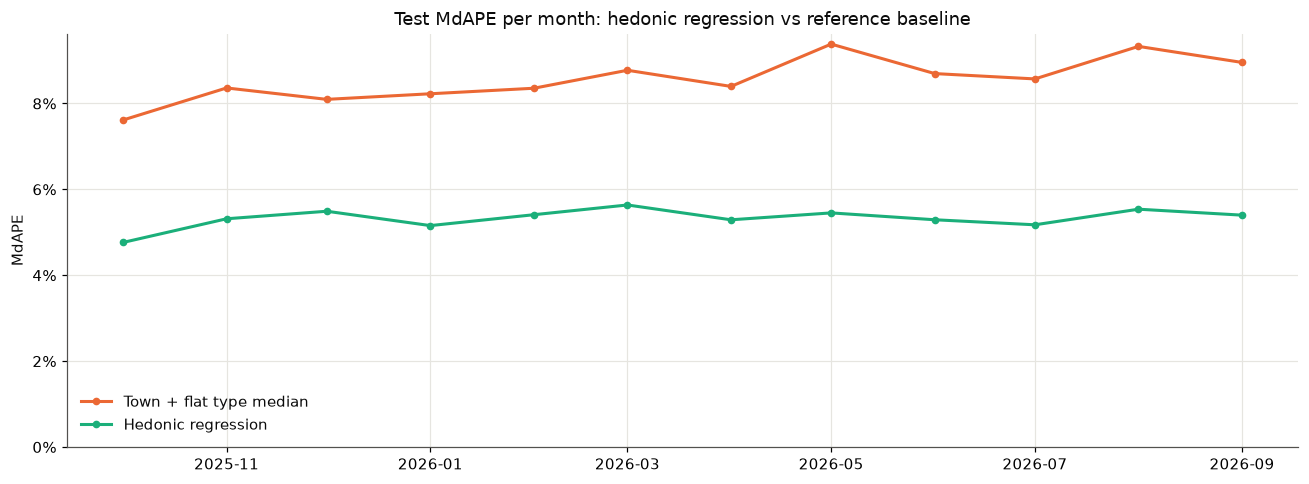

In [5]:
# MdAPE per test month: the model against the reference baseline
fig, ax = plt.subplots(figsize=(12, 4.5))
for color, name in zip(
    SERIES[1:3], ["Town + flat type median", "Hedonic regression"], strict=True
):
    scores = test[name]
    ax.plot(
        scores.index.to_timestamp(),
        scores["mdape"],
        color=color,
        marker="o",
        markersize=4,
        label=name,
    )
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_ylim(bottom=0)
ax.legend(frameon=False, loc="lower left")
ax.set(
    title="Test MdAPE per month: hedonic regression vs reference baseline",
    ylabel="MdAPE",
)
plt.tight_layout()

wins = (
    test["Hedonic regression"]["mdape"] < test["Town + flat type median"]["mdape"]
).sum()
print(f"The model beats the reference baseline in {wins} of the 12 test months")

### Findings (section 3)

- **The hedonic regression reaches MdAPE 5.3% on the test period**, against 8.6% for the reference baseline: about **40% lower error**. Half of the test sales are within 5.3% of their estimate; the average error falls from S\$82k to S\$46k.
- **It beats the baseline in all 12 test months**, and its worst month (5.6%) is better than the baseline's best: a consistent gain, not luck.
- **Test is slightly worse than validation** (5.3% vs 4.95%), as for the baselines: the window was chosen as the validation winner (the winner's curse), and the market moves. The test score is the honest one.

<a id="toc-4"></a>

## 4. What the model learned

A linear model on log price can be read directly: every coefficient is a price multiplier. To describe the market, the model is fitted once on all sales before the test period (expanding window, Jan 2017 to Sep 2025), so its month levels span the whole history.

<a id="toc-4a"></a>

### (a) A price index, checked against HDB's official one

The month levels are the market's movement with the mix of flats held constant. HDB publishes its own quarterly Resale Price Index (data.gov.sg, Singapore Open Data Licence); if our levels track it, the time handling measures what it should.

Correlation with the official index: 0.9999
Rise to 2025Q3: ours +57%, official +52%


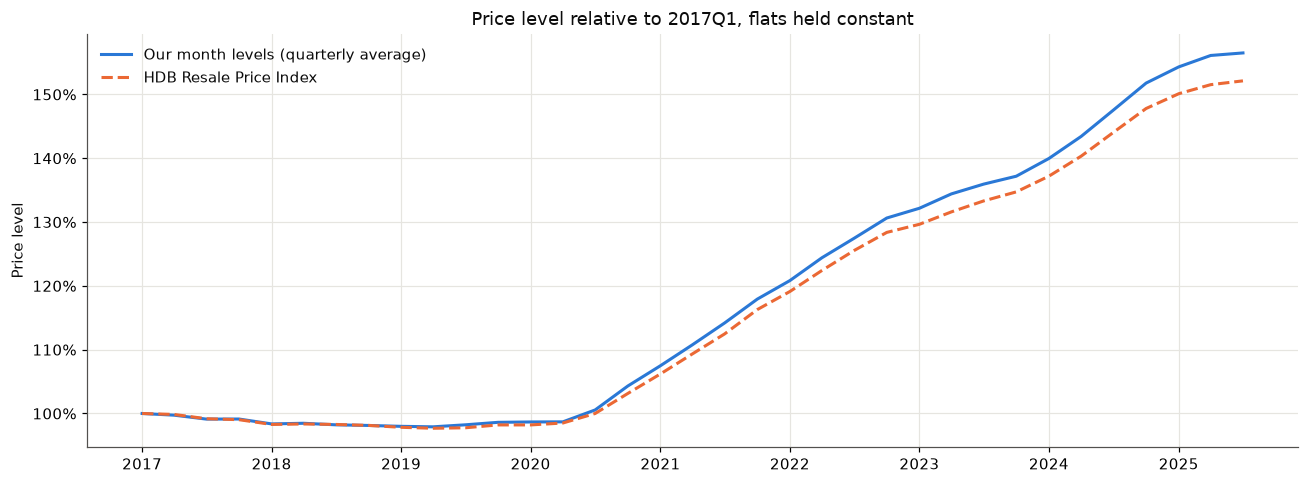

In [6]:
# One fit on all pre-test sales, to read what the model learned
pre_test = cleaned[cleaned["month"] < pd.Period(TEST_START, freq="M")]
described = HedonicRegression().fit(pre_test)

# Our monthly index, averaged by quarter and rebased to the first quarter
ours = described.price_index()
ours = ours.groupby(ours.index.asfreq("Q")).mean()
ours /= ours.iloc[0]

# HDB's official quarterly Resale Price Index, rebased to the same quarter
RPI_URL = "https://data.gov.sg/api/action/datastore_search?resource_id=d_14f63e595975691e7c24a27ae4c07c79&limit=1000"
with urllib.request.urlopen(RPI_URL, timeout=30) as response:
    records = json.load(response)["result"]["records"]
official = pd.Series(
    [float(r["index"]) for r in records],
    index=pd.PeriodIndex([r["quarter"].replace("-", "") for r in records], freq="Q"),
).loc[ours.index]
official /= official.iloc[0]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(
    ours.index.to_timestamp(),
    ours,
    color=SERIES[0],
    label="Our month levels (quarterly average)",
)
ax.plot(
    official.index.to_timestamp(),
    official,
    color=SERIES[1],
    linestyle="--",
    label="HDB Resale Price Index",
)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.legend(frameon=False, loc="upper left")
ax.set(
    title=f"Price level relative to {ours.index[0]}, flats held constant",
    ylabel="Price level",
)
plt.tight_layout()

print(f"Correlation with the official index: {ours.corr(official):.4f}")
print(
    f"Rise to {ours.index[-1]}: ours {ours.iloc[-1] - 1:+.0%}, official {official.iloc[-1] - 1:+.0%}"
)

<a id="toc-4b"></a>

### (b) The remaining lease effect

The lease bands' multipliers, all other drivers held constant: the model's version of the EDA's comparable-sales chart (section 3).

[0, 45)      0.577
[45, 50)     0.621
[50, 55)     0.693
[55, 60)     0.755
[60, 65)     0.814
[65, 70)     0.838
[70, 75)     0.856
[75, 80)     0.877
[80, 85)     0.907
[85, 90)     1.000
[90, 100)    1.053
dtype: float64

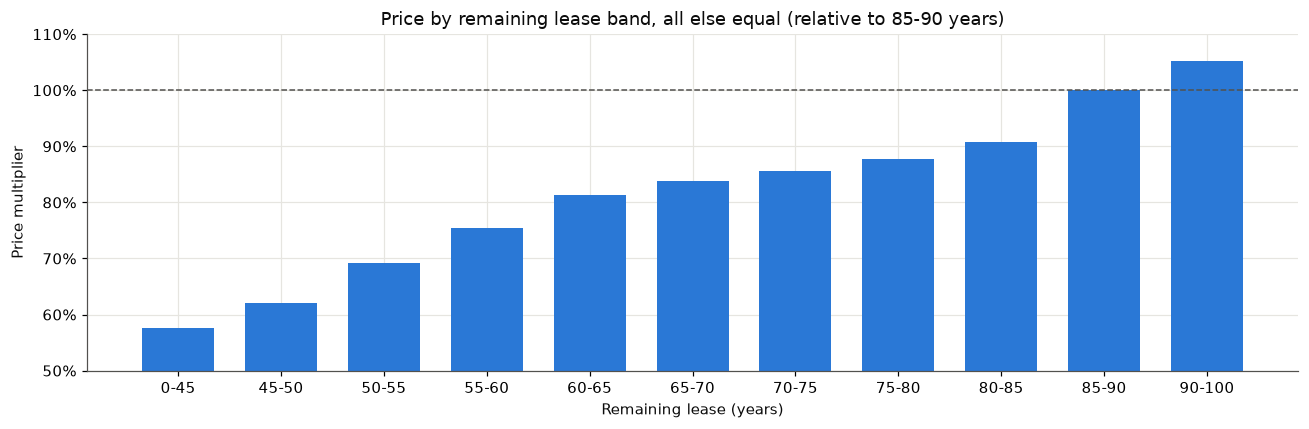

In [7]:
# Price multiplier of each 5-year lease band, all other drivers held constant
lease = described.effects("lease_band")
lease = lease / lease.loc["[85, 90)"]  # rebased: 1.0 = a flat with 85-90 years left
labels = [band.strip("[)").replace(", ", "-") for band in lease.index]

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(labels, lease.to_numpy(), color=SERIES[0], width=0.7)
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_ylim(0.5, 1.1)
ax.set_axisbelow(True)  # gridlines behind the bars
ax.set(
    title="Price by remaining lease band, all else equal (relative to 85-90 years)",
    xlabel="Remaining lease (years)",
    ylabel="Price multiplier",
)
plt.tight_layout()
lease.round(3)

**Bands or a straight line?** The steps between bands aren't even (about 6 points per 5 years below 65 years, about 2 from 65 to 85, then a 9-point jump at 85), which suggests the effect isn't linear. Rather than judge by eye, the alternative is tested: the same model with remaining lease as a single straight-line feature (each extra year adds the same percentage), on the validation period.

In [8]:
# Lease as 5-year bands vs one straight line on log price, same 12-month window, validation period
lease_shape = {
    shape: score(
        backtest(
            cleaned, HedonicRegression(lease=shape), train_months=12, end=TEST_START
        )
    )
    for shape in ["bands", "linear"]
}
for shape, scores in lease_shape.items():
    print(
        f"{shape:>7}: validation MdAPE {scores['mdape'].mean():.2%}, MAE S${scores['mae'].mean():,.0f}"
    )
wins = (lease_shape["bands"]["mdape"] < lease_shape["linear"]["mdape"]).sum()
print(f"Bands beat the straight line in {wins} of the 12 validation months")

  bands: validation MdAPE 4.95%, MAE S$41,747
 linear: validation MdAPE 5.36%, MAE S$43,700
Bands beat the straight line in 12 of the 12 validation months


### Findings (section 4)

- **The month levels track HDB's official Resale Price Index almost exactly** (correlation 0.9999 over 2017–2025): flat to 2020, then a steady rise. Ours rises slightly more (+57% vs +52% by 2025 Q3), a gap that opens during the rise and plausibly comes from the two methods weighting the mix of flats differently. Turning points and levels match: the time handling measures the market, which independently supports ADR-0005.
- **Holding every other driver constant, the remaining lease matters all along, not in three flat phases.** From 85–90 years left, price drops about 9% in the next band (80–85), then declines gently (2–3% per 5 years) down to about 60 years, then steeply below 60 (7–10% per 5 years), to 58% of the reference under 45 years. The steep part matches the financing rules (CPF use and HDB loans reduced when the lease doesn't cover the youngest buyer to age 95) and the accelerating decline of a lease's value (Bala's curve).
- **The effect isn't linear, and the bands earn their place:** forcing a straight line raises the validation MdAPE from 4.95% to 5.36%, worse in all 12 validation months. The best straight line through the band levels misses some bands by up to 6.5%, more than the model's typical error, and its gaps alternate in sign (too high, too low, too high), the signature of a curve forced into a line.
- **The EDA's flat 55–80 plateau was partly confounding.** Comparing sales within the same town and month didn't hold size and design constant, and older flats tend to be larger and of different designs. Only a model that sees all drivers together separates the lease effect, which is the point made at the end of the EDA.

<a id="toc-5"></a>

## 5. Summary: decisions

| Finding | Decision |
|---|---|
| Hedonic regression, 12-month window: test MdAPE 5.3% (S$46k MAE), 40% below the reference baseline, better in all 12 test months | **The current best model**, and the one every later model is compared with |
| Expanding is the worst window; 3–12 months tie | Training window fixed at **12 months**, chosen on validation |
| Month levels track HDB's official index (0.9999) | Time handled as month levels, the latest carried forward (project ADR-0005) |
| Sliding windows beat expanding even with month levels: the effects drift over time | The residual analysis checks which effects drift, and how |
| The lease effect is non-linear all along: bands beat a straight line in 12 of 12 validation months | 5-year bands kept; a smoother shape (splines) only if the residuals ask for it |

**Next: the residual analysis** (step 2, sub-step 6): where is this model systematically wrong (by town, lease, size, flat model, over time)? It decides three things:
- **The primary metric** and the "good enough" threshold.
- **Geocoding (OneMap):** if errors cluster within towns, finer location is worth adding.
- **Whether a tree-based model is justified.** Trees build thresholds and **interactions** (e.g. a lease discount that differs by town) automatically, where a linear model only adds independent effects. The lease bands already give this model its thresholds, so a tree earns its place only if the residuals show interactions the linear model can't express, and it's kept only if it clearly beats this model on the same backtest.